## Chapter 3: Building & Comparing Surrogate Models

We'll build all 3 architectures × all 3 noise-handling strategies, then
compare how well each predicts REAL pilot yield on 25 recipes the model
has never seen before. Lower RMSE = better.

In [11]:
import numpy as np
import pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

df = pd.read_csv("task1_2_data.csv")
df_expl = df[df["phase"] == "exploration"].reset_index(drop=True)

params = ["T", "pH", "F1", "F2", "F3"]
print("Exploration rows:", len(df_expl))
print(df_expl["scale"].value_counts())

Exploration rows: 384
scale
micro    128
bench    128
pilot    128
Name: count, dtype: int64


### Split recipes into train/test

We hold out 25 of the 128 recipes. Their PILOT yield is what every
architecture will try to predict — that's the number that actually
matters for optimization.

In [12]:
np.random.seed(42)
all_recipe_ids = df_expl["recipe_id"].unique()
test_recipe_ids = np.random.choice(all_recipe_ids, size=25, replace=False)
train_recipe_ids = np.array([r for r in all_recipe_ids if r not in test_recipe_ids])

print(f"Train recipes: {len(train_recipe_ids)}, Test recipes: {len(test_recipe_ids)}")

Train recipes: 103, Test recipes: 25


### Noise numbers from Chapter 2

Hard-coded here so this notebook can run by itself, without re-running
the earlier chapter.

In [13]:
noise_std = {"micro": 0.0196, "bench": 0.0588, "pilot": 0.0052}
noise_var = {scale: std**2 for scale, std in noise_std.items()}
print(noise_var)

{'micro': 0.00038416, 'bench': 0.0034574399999999996, 'pilot': 2.704e-05}


### The 3 ways of handling GP noise

Each mode configures the WhiteKernel differently, using the SAME starting
number, our measured variance.

In [14]:
def make_noise_kernel(variance, mode):
    if mode == "fixed":
        # Trust our measured noise completely — GP can't change it
        return WhiteKernel(noise_level=variance, noise_level_bounds="fixed")
    elif mode == "starting_point":
        # Use our number as a guess, let the GP fully re-optimize it
        return WhiteKernel(noise_level=variance, noise_level_bounds=(1e-6, 1e2))
    elif mode == "bounded":
        # Let the GP search, but stay within 10x of our measured value
        return WhiteKernel(noise_level=variance, noise_level_bounds=(variance / 10, variance * 10))
    else:
        raise ValueError("unknown mode")

noise_modes = ["fixed", "starting_point", "bounded"]

### A reusable "fit one GP and score it" helper

Just to avoid repeating the same 5 lines nine separate times.

In [15]:
def fit_and_score(X_train, y_train, X_test, y_test, variance, mode):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    kernel = ConstantKernel(1.0) * RBF(length_scale=np.ones(X_train.shape[1])) \
             + make_noise_kernel(variance, mode)

    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3, random_state=42, normalize_y=True)
    gp.fit(X_train_scaled, y_train)

    y_pred = gp.predict(X_test_scaled)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    return rmse

results = []  # every combo's score lands here

## Architecture A: One GP for everything (fidelity as a 6th input)

Stack micro + bench + TRAIN-only pilot rows together, adding a column for
which scale each row is (0=micro, 1=bench, 2=pilot). One GP learns the
whole 6D relationship.

Caveat: WhiteKernel only supports ONE noise value for the whole dataset,
even though we know the 3 scales are differently noisy. We approximate
with a noise-weighted average.

In [16]:
fidelity_map = {"micro": 0, "bench": 1, "pilot": 2}

train_rows_A = df_expl[
    (df_expl["scale"].isin(["micro", "bench"])) |
    ((df_expl["scale"] == "pilot") & (df_expl["recipe_id"].isin(train_recipe_ids)))
]
test_rows_A = df_expl[(df_expl["scale"] == "pilot") & (df_expl["recipe_id"].isin(test_recipe_ids))]

X_train_A = train_rows_A[params].copy()
X_train_A["fidelity"] = train_rows_A["scale"].map(fidelity_map)
y_train_A = train_rows_A["yield"].values

X_test_A = test_rows_A[params].copy()
X_test_A["fidelity"] = 2  # pilot
y_test_A = test_rows_A["yield"].values

counts = train_rows_A["scale"].value_counts()
pooled_variance_A = sum(noise_var[s] * counts[s] for s in counts.index) / counts.sum()

for mode in noise_modes:
    rmse = fit_and_score(X_train_A.values, y_train_A, X_test_A.values, y_test_A, pooled_variance_A, mode)
    results.append({"architecture": "A: single 6D GP", "noise_mode": mode, "rmse": rmse})
    print(f"Architecture A, noise={mode:15s} -> RMSE = {rmse:.4f}")

Architecture A, noise=fixed           -> RMSE = 0.2513


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Architecture A, noise=starting_point  -> RMSE = 0.2473
Architecture A, noise=bounded         -> RMSE = 0.2477


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 0.000137746495821727. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


## Architecture B: 3 separate GPs + manual bias correction

Each scale gets its own GP with its own real noise value — the one place
we use our measured noise exactly as-is. Micro/bench predictions are
converted to "pilot-equivalent" using a straight-line fit learned ONLY
from train recipes (so we're not cheating with test data).

In [17]:
pilot_train_rows = df_expl[(df_expl["scale"] == "pilot") & (df_expl["recipe_id"].isin(train_recipe_ids))]
pilot_test_rows = df_expl[(df_expl["scale"] == "pilot") & (df_expl["recipe_id"].isin(test_recipe_ids))]

X_pilot_train, y_pilot_train = pilot_train_rows[params].values, pilot_train_rows["yield"].values
X_pilot_test, y_pilot_test = pilot_test_rows[params].values, pilot_test_rows["yield"].values

# Pilot GP predicting pilot directly — the "gold standard" to beat
for mode in noise_modes:
    rmse = fit_and_score(X_pilot_train, y_pilot_train, X_pilot_test, y_pilot_test, noise_var["pilot"], mode)
    results.append({"architecture": "B: pilot-only GP", "noise_mode": mode, "rmse": rmse})
    print(f"Architecture B (pilot-only), noise={mode:15s} -> RMSE = {rmse:.4f}")

# Now try predicting pilot yield using cheap-scale GPs + correction instead
for cheap_scale in ["bench", "micro"]:
    cheap_train_rows = df_expl[(df_expl["scale"] == cheap_scale) & (df_expl["recipe_id"].isin(train_recipe_ids))]
    cheap_test_rows = df_expl[(df_expl["scale"] == cheap_scale) & (df_expl["recipe_id"].isin(test_recipe_ids))]

    X_cheap_train, y_cheap_train = cheap_train_rows[params].values, cheap_train_rows["yield"].values
    X_cheap_test = cheap_test_rows[params].values

    pair = pd.merge(
        cheap_train_rows[["recipe_id", "yield"]].rename(columns={"yield": "cheap_yield"}),
        pilot_train_rows[["recipe_id", "yield"]].rename(columns={"yield": "pilot_yield"}),
        on="recipe_id"
    )
    bias_model = LinearRegression().fit(pair[["cheap_yield"]], pair["pilot_yield"])
    print(f"{cheap_scale} -> pilot correction: intercept={bias_model.intercept_:.3f}, slope={bias_model.coef_[0]:.3f}")

    for mode in noise_modes:
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_cheap_train)
        X_test_scaled = scaler.transform(X_cheap_test)

        kernel = ConstantKernel(1.0) * RBF(length_scale=np.ones(X_cheap_train.shape[1])) \
                 + make_noise_kernel(noise_var[cheap_scale], mode)
        gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3, random_state=42, normalize_y=True)
        gp.fit(X_train_scaled, y_cheap_train)

        raw_pred = gp.predict(X_test_scaled)
        corrected_pred = bias_model.predict(raw_pred.reshape(-1, 1))
        rmse = np.sqrt(mean_squared_error(y_pilot_test, corrected_pred))

        results.append({"architecture": f"B: {cheap_scale}-GP + correction", "noise_mode": mode, "rmse": rmse})
        print(f"Architecture B ({cheap_scale}+correction), noise={mode:15s} -> RMSE = {rmse:.4f}")

Architecture B (pilot-only), noise=fixed           -> RMSE = 0.4828
Architecture B (pilot-only), noise=starting_point  -> RMSE = 0.4828
Architecture B (pilot-only), noise=bounded         -> RMSE = 0.4828
bench -> pilot correction: intercept=-0.709, slope=0.614


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Architecture B (bench+correction), noise=fixed           -> RMSE = 0.4365


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnin

Architecture B (bench+correction), noise=starting_point  -> RMSE = 0.4887


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 0.00034574399999999993. Decreasing the bound and calling fit again may find a bette

... (2 outputs left out)

Architecture B (micro+correction), noise=fixed           -> RMSE = 0.6407


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnin

Architecture B (micro+correction), noise=starting_point  -> RMSE = 0.6407
Architecture B (micro+correction), noise=bounded         -> RMSE = 0.6407


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 3.8416e-05. Decreasing the bound and calling fit again may find a better value.
  w

## Architecture C: Two-fidelity GP (drop micro, keep bench + pilot)

Same idea as Architecture A, but testing whether dropping the weakly
correlated micro scale (R²=0.74) and keeping only the strong bench proxy
(R²=0.99) actually improves things.

In [18]:
train_rows_C = df_expl[
    (df_expl["scale"] == "bench") |
    ((df_expl["scale"] == "pilot") & (df_expl["recipe_id"].isin(train_recipe_ids)))
]
test_rows_C = df_expl[(df_expl["scale"] == "pilot") & (df_expl["recipe_id"].isin(test_recipe_ids))]

X_train_C = train_rows_C[params].copy()
X_train_C["fidelity"] = train_rows_C["scale"].map(fidelity_map)
y_train_C = train_rows_C["yield"].values

X_test_C = test_rows_C[params].copy()
X_test_C["fidelity"] = 2
y_test_C = test_rows_C["yield"].values

counts_C = train_rows_C["scale"].value_counts()
pooled_variance_C = sum(noise_var[s] * counts_C[s] for s in counts_C.index) / counts_C.sum()

for mode in noise_modes:
    rmse = fit_and_score(X_train_C.values, y_train_C, X_test_C.values, y_test_C, pooled_variance_C, mode)
    results.append({"architecture": "C: bench+pilot GP", "noise_mode": mode, "rmse": rmse})
    print(f"Architecture C, noise={mode:15s} -> RMSE = {rmse:.4f}")

Architecture C, noise=fixed           -> RMSE = 0.7025


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-06. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Architecture C, noise=starting_point  -> RMSE = 0.7063
Architecture C, noise=bounded         -> RMSE = 0.7059


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 0.00019278677056277054. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


## Comparing everything

Sorted best (lowest RMSE) to worst.

In [19]:
results_df = pd.DataFrame(results).sort_values("rmse").reset_index(drop=True)
results_df

,architecture,noise_mode,rmse
0,A: single 6D GP,starting_point,0.247337
1,A: single 6D GP,bounded,0.247742
2,A: single 6D GP,fixed,0.251337
3,B: bench-GP + correction,fixed,0.436474
4,B: pilot-only GP,bounded,0.482754
5,B: pilot-only GP,starting_point,0.482754
6,B: pilot-only GP,fixed,0.482765
7,B: bench-GP + correction,bounded,0.488697
8,B: bench-GP + correction,starting_point,0.488747
9,B: micro-GP + correction,fixed,0.640667


In [20]:
# Check whether the "good" models are actually predicting anything meaningful
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_pilot_train)
X_test_scaled = scaler.transform(X_pilot_test)

kernel = ConstantKernel(1.0) * RBF(length_scale=np.ones(X_pilot_train.shape[1])) \
         + make_noise_kernel(noise_var["pilot"], "fixed")
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3, random_state=42, normalize_y=True)
gp.fit(X_train_scaled, y_pilot_train)

y_pred = gp.predict(X_test_scaled)
print("Predictions:", np.round(y_pred[:10], 3))
print("Actual:     ", np.round(y_pilot_test[:10], 3))
print("Fitted kernel:", gp.kernel_)

Predictions: [1.531 1.499 1.524 1.7   1.575 0.505 2.321 1.478 1.463 1.708]
Actual:      [1.313 1.376 1.525 1.821 1.273 1.224 1.805 1.526 1.239 1.745]
Fitted kernel: 1.04**2 * RBF(length_scale=[5.92e+03, 5.07e+04, 0.826, 0.509, 0.118]) + WhiteKernel(noise_level=2.7e-05)


## Chapter 3.5: Sanity-Checking "T and pH Don't Matter"

The GP's length scales suggested yield barely depends on T and pH.
Before trusting that, we check it 3 independent ways that don't rely
on the GP's optimizer at all.

In [21]:
# Simplest possible check: does yield move at all with each parameter?
pilot_train_data = df_expl[(df_expl["scale"] == "pilot") & (df_expl["recipe_id"].isin(train_recipe_ids))]

correlations = pilot_train_data[params + ["yield"]].corr()["yield"].drop("yield")
print("Correlation of each parameter with pilot yield:")
print(correlations.sort_values(key=abs, ascending=False))

Correlation of each parameter with pilot yield:
F3    0.185489
F1    0.107386
pH    0.098557
T    -0.061636
F2   -0.021060
Name: yield, dtype: float64


### Check 2: binned trend plot

Correlation only catches STRAIGHT-LINE relationships. If yield depends on
T in a curved way (e.g. peaks in the middle), correlation could look near
zero even though T matters a lot. Binning catches that.

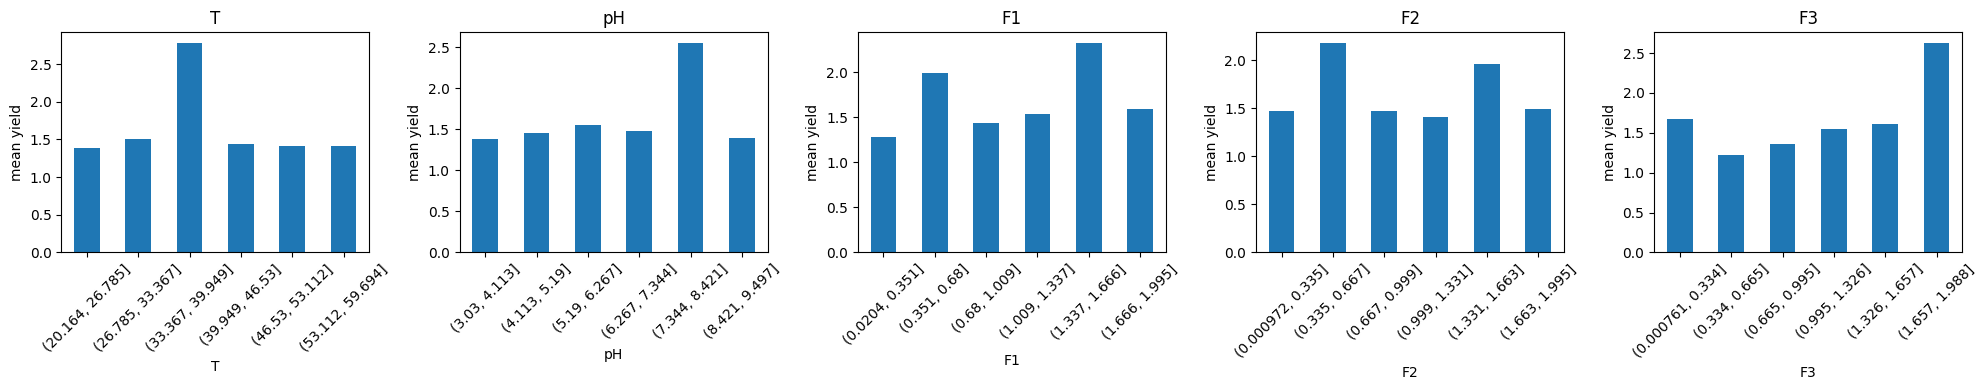

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, param in zip(axes, params):
    bins = pd.cut(pilot_train_data[param], bins=6)
    binned_mean = pilot_train_data.groupby(bins, observed=True)["yield"].mean()
    binned_mean.plot(kind="bar", ax=ax)
    ax.set_title(param)
    ax.set_ylabel("mean yield")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Check 3: an independent model (Random Forest)

Random Forest ranks feature importance by how much each parameter
actually reduces prediction error when it splits on it — a completely
different mechanism from the GP's length scale. If both agree, that's
strong evidence, not a modeling coincidence.

In [23]:
from sklearn.ensemble import RandomForestRegressor

X_pilot_train = pilot_train_data[params].values
y_pilot_train = pilot_train_data["yield"].values

rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X_pilot_train, y_pilot_train)

importance = pd.Series(rf.feature_importances_, index=params).sort_values(ascending=False)
print("Random Forest feature importance:")
print(importance)

Random Forest feature importance:
F3    0.676255
pH    0.151323
F2    0.071802
F1    0.058765
T     0.041855
dtype: float64


### Check 4: did the GP actually converge, or hit a search boundary?

If T/pH's length scale is sitting right at the GP's upper search limit,
that's a sign the optimizer wanted to go even flatter but got capped —
not necessarily proof T/pH are truly irrelevant.

In [24]:
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

kernel_wide = ConstantKernel(1.0) * RBF(
    length_scale=np.ones(len(params)),
    length_scale_bounds=(1e-3, 1e7)  # much wider than sklearn's default (1e-5, 1e5)
) + WhiteKernel(noise_level=noise_var["pilot"], noise_level_bounds=(1e-6, 1e2))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pilot_train)

gp_check = GaussianProcessRegressor(kernel=kernel_wide, n_restarts_optimizer=15, random_state=42, normalize_y=True)
gp_check.fit(X_scaled, y_pilot_train)

print("Widened-search kernel:", gp_check.kernel_)

Widened-search kernel: 0.863**2 * RBF(length_scale=[0.0707, 0.276, 1e+07, 1e+07, 9.83]) + WhiteKernel(noise_level=9.7e-06)


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 10000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [25]:
# Check: does F3's dominance survive removing the 2 highest-yield outlier recipes?
pilot_train_sorted = pilot_train_data.sort_values("yield", ascending=False)
print(pilot_train_sorted[["recipe_id", "T", "pH", "F1", "F2", "F3", "yield"]].head(3))

pilot_no_outliers = pilot_train_data[pilot_train_data["yield"] < pilot_train_data["yield"].quantile(0.95)]

corr_no_outliers = pilot_no_outliers[params + ["yield"]].corr()["yield"].drop("yield")
print("\nCorrelation without top 5% outliers:")
print(corr_no_outliers.sort_values(key=abs, ascending=False))

rf2 = RandomForestRegressor(n_estimators=300, random_state=42)
rf2.fit(pilot_no_outliers[params].values, pilot_no_outliers["yield"].values)
print("\nRF importance without outliers:")
print(pd.Series(rf2.feature_importances_, index=params).sort_values(ascending=False))

     recipe_id          T        pH        F1        F2        F3      yield
221         73  35.959092  7.532484  1.605257  0.617585  1.701267  14.094424
29           9  35.600859  7.917311  0.575853  1.365486  0.311931   9.873677
332        110  33.813484  5.671617  0.618111  1.860480  1.739480   2.433550

Correlation without top 5% outliers:
F3    0.914033
F1    0.347867
pH    0.076615
T    -0.049814
F2   -0.027431
Name: yield, dtype: float64

RF importance without outliers:
F3    0.884487
F1    0.070864
pH    0.026222
F2    0.012578
T     0.005849
dtype: float64
